<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Build a review queue from source structure

**Which functions exceed a chosen span, and why should nested spans not be added together?**
We will parse a synthetic Python module through the real VGI worker, check parser
recovery signals, and join structural symbols to custom tree-sitter captures.
SQL will build a review queue and count unique covered lines; charts will show
nesting and the chosen span threshold.

The source is teaching text and is never imported or executed. A line-span threshold
is a configurable way to choose review candidates, not a measure of correctness,
complexity or developer productivity.

## Choose a review threshold

`MIN_SPAN_LINES` is an integer from 1 to 24, inclusive. The default is **4**;
the end experiment raises it to **8**. A function qualifies when its inclusive
physical span is **at least** this many lines. Comments, docstrings, blank lines
and nested definitions inside that span still count. The source text stays fixed.
Restart and run all after editing. [Setup instructions](README.md).

In [1]:
MIN_SPAN_LINES = 4

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.patches import Patch
from notebook_support import finish, prose, theme

if (
    isinstance(MIN_SPAN_LINES, bool)
    or not isinstance(MIN_SPAN_LINES, int)
    or not 1 <= MIN_SPAN_LINES <= 24
):
    raise ValueError("MIN_SPAN_LINES must be an integer from 1 through 24.")
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/vgi-code/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/vgi-code/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/vgi-code/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-code/notebooks/pyproject.toml.

## Connect to the native release

The visible `github-auto` location retrieves, verifies and caches the published
worker. No local Rust build or source checkout is required. The discovery table
lists the grammar names available from this worker release.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'code' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-code@v0.4.0');
SELECT * FROM code.main.supported_languages() ORDER BY language;

,language
0,c
1,cpp
2,go
3,java
4,javascript
5,json
6,python
7,rust
8,typescript


## Keep the source and its availability visible

A SQL macro holds one constant source string so the table functions can reuse it
without hiding the text in Python. The module includes a nested helper and two
other top-level functions. The input inventory also contains incomplete Python,
a missing source value and an unrecognized filename extension.

The worker's scalar functions accept per-row source and language columns. Its table
functions require constant-foldable inputs; the literal-valued macro satisfies that
requirement. No correlated table-function call is needed.

In [5]:
%%sql
CREATE OR REPLACE MACRO example_source() AS $$# Synthetic teaching module: text only.
def prepare(values):
    """Keep nonnegative values and normalize them."""
    def clamp(value):
        if value < 0:
            return 0
        return value

    cleaned = [clamp(value) for value in values]
    total = sum(cleaned)
    if total == 0:
        return cleaned
    return [value / total for value in cleaned]


def summarize(values):
    """Return count and total."""
    count = len(values)
    total = sum(values)
    return count, total


def label():
    return "sample"
$$;
CREATE OR REPLACE TABLE files AS
SELECT * FROM (VALUES
 ('example.py', example_source()),
 ('truncated.py', $$def retained():
    return 1
def unfinished(:
$$),
 ('missing.py', NULL),
 ('notes.txt', 'A text note with no selected grammar.')
) AS t(path, source);
SELECT path, source, code.main.language_of(path) AS inferred_language FROM files ORDER BY path;

,path,source,inferred_language
0,example.py,# Synthetic teaching module: text only.\ndef p...,python
1,missing.py,None,python
2,notes.txt,A text note with no selected grammar.,None
3,truncated.py,def retained():\n return 1\ndef unfinished(:\n,python


## Recovery signals come before ranking

Tree-sitter can extract structure from incomplete source. Capture both `ERROR`
nodes and zero-width `MISSING` nodes; checking just error captures can miss a
recovery condition. Count the missing-node captures even when their returned text
is an empty string. Unknown language and missing source remain unavailable,
not zero-function documents.

In [6]:
%%sql
CREATE OR REPLACE TABLE source_metrics AS
WITH languages AS (SELECT *, code.main.language_of(path) AS language FROM files)
SELECT path, language, source IS NULL AS source_missing,
 code.main.count_lines(source) AS physical_lines,
 CASE WHEN language IS NOT NULL AND source IS NOT NULL
      THEN code.main.loc(source,language) END AS worker_loc,
 CASE WHEN language IS NOT NULL AND source IS NOT NULL
      THEN code.main.count_functions(source,language) END AS function_count,
 CASE WHEN language IS NOT NULL AND source IS NOT NULL
      THEN code.main.ts_query(source,language,'(ERROR) @error') END AS error_captures,
 CASE WHEN language IS NOT NULL AND source IS NOT NULL
      THEN code.main.ts_query(source,language,'(MISSING) @missing') END AS missing_captures
FROM languages;
CREATE OR REPLACE TABLE source_audit AS
SELECT *, len(error_captures) AS error_nodes, len(missing_captures) AS missing_nodes,
 CASE WHEN source_missing THEN 'Missing source'
      WHEN language IS NULL THEN 'Unknown language'
      WHEN len(error_captures)+len(missing_captures)>0 THEN 'Parser recovery'
      ELSE 'No recovery nodes' END AS parse_status
FROM source_metrics;
SELECT path, language, physical_lines, worker_loc, function_count,
 error_nodes, missing_nodes, parse_status FROM source_audit ORDER BY path;

,path,language,physical_lines,worker_loc,function_count,error_nodes,missing_nodes,parse_status
0,example.py,python,24,18,4,0,0,No recovery nodes
1,missing.py,python,<NA>,<NA>,<NA>,<NA>,<NA>,Missing source
2,notes.txt,None,1,<NA>,<NA>,<NA>,<NA>,Unknown language
3,truncated.py,python,3,3,2,0,1,Parser recovery


In [7]:
%%sql recovery <<
SELECT path, function_count, error_captures, missing_captures
FROM source_audit WHERE parse_status='Parser recovery' ORDER BY path;

In [8]:
recovery = globals()["recovery"]
display(recovery)
row = recovery.iloc[0]
prose(
    f"The incomplete fixture still yields **{int(row.function_count)} function definitions**, "
    f"with **{len(row.error_captures)} ERROR captures** and "
    f"**{len(row.missing_captures)} MISSING captures**. Its missing-token text is empty, "
    "but the capture itself matters. We retain this row for review and use only the "
    "complete `example.py` module below. Absence of recovery nodes is a parser observation, "
    "not a substitute for a compiler, tests or semantic validation."
)

,path,function_count,error_captures,missing_captures
0,truncated.py,2,[],[]


The incomplete fixture still yields **2 function definitions**, with **0 ERROR captures** and **1 MISSING captures**. Its missing-token text is empty, but the capture itself matters. We retain this row for review and use only the complete `example.py` module below. Absence of recovery nodes is a parser observation, not a substitute for a compiler, tests or semantic validation.

## Join symbol names to full definition captures

The selected module must have no reported recovery nodes. Extract symbols for names
and one-based spans, then use a custom tree-sitter query to retrieve each full function
definition. Join by the returned start/end lines. In this fixture those spans uniquely
identify functions; the SQL checks that assumption before using the join.

An enclosing function's capture includes its nested function. The inclusive span is
`end_line - start_line + 1`, which differs from the worker's nonblank, noncomment LOC.

In [9]:
%%sql
SELECT CASE WHEN parse_status='No recovery nodes' THEN 'Selected module passed recovery screen'
 ELSE error('Review parser recovery before building the queue') END AS recovery_screen
FROM source_audit WHERE path='example.py';
CREATE OR REPLACE TABLE symbols AS
SELECT * FROM code.main.symbols(example_source(),'python') WHERE kind='function';
CREATE OR REPLACE TABLE definitions AS
SELECT * FROM code.main.ts_nodes(example_source(),'python','(function_definition) @definition');
SELECT CASE WHEN count(*)=count(DISTINCT (start_line,end_line)) THEN 'Unique function spans'
 ELSE error('Line spans are ambiguous; do not join them blindly') END AS span_check FROM symbols;
SELECT CASE WHEN count(*)=count(DISTINCT (start_line,end_line)) THEN 'Unique definition captures'
 ELSE error('Definition spans are ambiguous') END AS capture_check FROM definitions;
CREATE OR REPLACE TABLE functions AS
SELECT s.name, s.start_line, s.end_line, s.end_line-s.start_line+1 AS span_lines,
 d.text AS definition_source,
 EXISTS (SELECT 1 FROM symbols parent WHERE parent.start_line<s.start_line
         AND parent.end_line>=s.end_line) AS nested
FROM symbols s JOIN definitions d USING(start_line,end_line);
SELECT name, start_line, end_line, span_lines, nested FROM functions ORDER BY start_line;

,name,start_line,end_line,span_lines,nested
0,prepare,2,13,12,False
1,clamp,4,7,4,True
2,summarize,16,20,5,False
3,label,23,24,2,False


## Plot spans without losing nesting

The bars occupy the original line positions. A nested helper's lines are also inside
its parent span, so adding the bars' lengths would count those physical lines twice.
The labels retain the function name and exact line range.

In [10]:
%%sql spans <<
SELECT name, start_line, end_line, span_lines, nested FROM functions ORDER BY start_line;

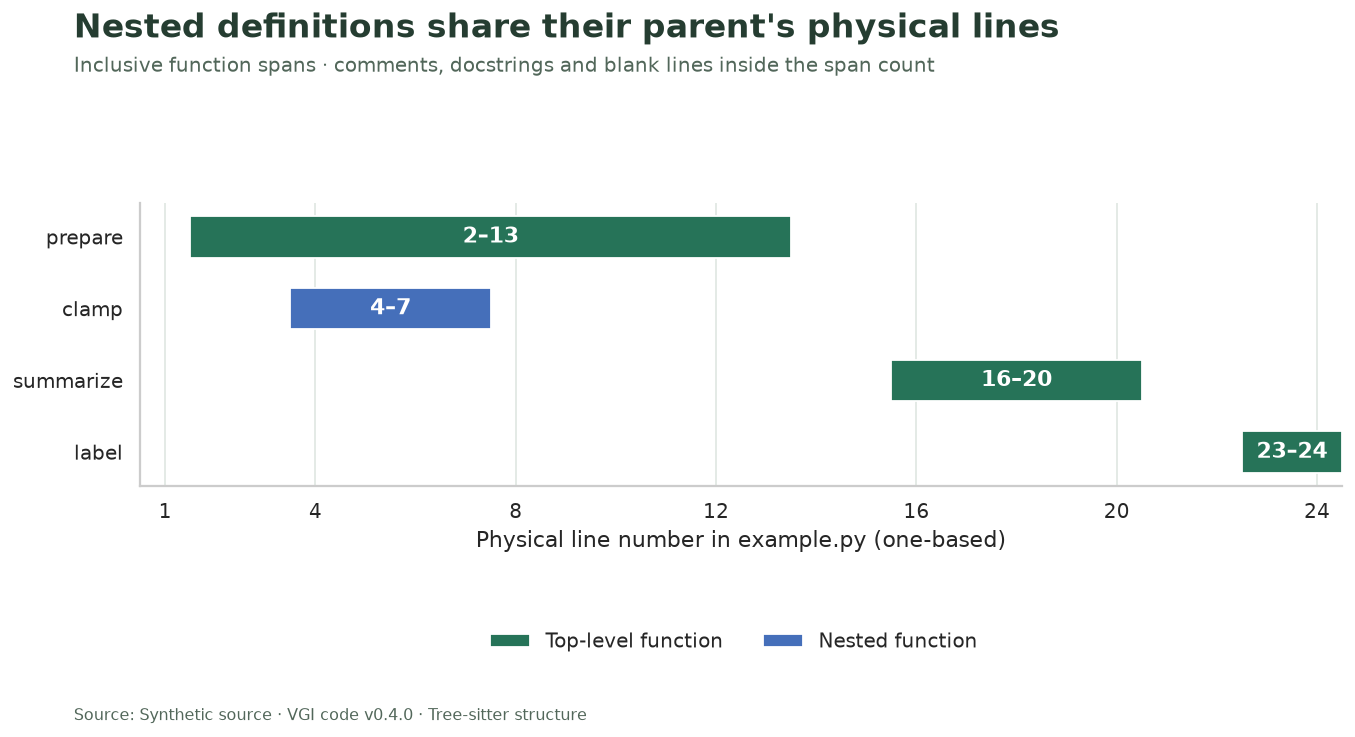

In [11]:
spans = globals()["spans"]
fig, ax = plt.subplots(figsize=(10.8, 5.7))
y = np.arange(len(spans))
colors = ["#456fba" if value else "#267358" for value in spans.nested]
ax.barh(y, spans.span_lines, left=spans.start_line - 0.5, color=colors, height=0.58)
for i, row in enumerate(spans.itertuples(index=False)):
    ax.text(
        row.start_line + (row.span_lines - 1) / 2,
        i,
        f"{row.start_line}–{row.end_line}",
        ha="center",
        va="center",
        color="white",
        weight="bold",
    )
ax.set_yticks(y, spans.name)
ax.invert_yaxis()
ax.set_xlim(0.5, 24.5)
ax.set_xticks([1, 4, 8, 12, 16, 20, 24])
ax.set_xlabel("Physical line number in example.py (one-based)")
ax.grid(axis="y", visible=False)
fig.legend(
    handles=[
        Patch(facecolor="#267358", label="Top-level function"),
        Patch(facecolor="#456fba", label="Nested function"),
    ],
    loc="center",
    bbox_to_anchor=(0.55, 0.13),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Nested definitions share their parent's physical lines",
    "Inclusive function spans · comments, docstrings and blank lines inside the span count",
    f"function-spans-{MIN_SPAN_LINES}.png",
    bottom=0.22,
)

## Count unique covered lines with SQL

Expand each function's inclusive range to one row per line, then count distinct line
numbers. Keep the sum of spans for comparison and show the parser's LOC separately;
these measures have different definitions, so none should silently replace another.

In [12]:
%%sql accounting <<
WITH coverage AS (
 SELECT name, unnest(range(start_line,end_line+1)) AS line_number FROM functions
)
SELECT (SELECT sum(span_lines) FROM functions) AS sum_of_function_spans,
 count(DISTINCT line_number) AS unique_lines_in_functions,
 count(*)-count(DISTINCT line_number) AS repeated_line_memberships,
 (SELECT physical_lines FROM source_audit WHERE path='example.py') AS module_physical_lines,
 (SELECT worker_loc FROM source_audit WHERE path='example.py') AS module_worker_loc
FROM coverage;

In [13]:
accounting = globals()["accounting"]
display(accounting)
a = accounting.iloc[0]
prose(
    f"Adding function spans gives **{int(a.sum_of_function_spans)} line memberships**, "
    f"but they cover only **{int(a.unique_lines_in_functions)} distinct physical lines**. "
    f"The difference is **{int(a.repeated_line_memberships)} repeated memberships** from nesting. "
    f"The entire module has **{int(a.module_physical_lines)} physical lines** and "
    f"**{int(a.module_worker_loc)} worker LOC**. These are explicit definitions, not competing "
    "estimates of one interchangeable metric."
)

,sum_of_function_spans,unique_lines_in_functions,repeated_line_memberships,module_physical_lines,module_worker_loc
0,23.0,19,4,24,18


Adding function spans gives **23 line memberships**, but they cover only **19 distinct physical lines**. The difference is **4 repeated memberships** from nesting. The entire module has **24 physical lines** and **18 worker LOC**. These are explicit definitions, not competing estimates of one interchangeable metric.

## Build the threshold-based review queue

Select functions with inclusive span at least the visible threshold, retaining the
nested flag. Order by span and then name for stable display. The chart shows every
function, including those below the threshold, so an empty or small queue does not
look like missing data. The dashed line is a chosen review rule, not a quality boundary.

In [14]:
%%sql queue <<
SELECT name, start_line, end_line, span_lines, nested,
 span_lines >= {{ MIN_SPAN_LINES }} AS selected
FROM functions ORDER BY span_lines DESC,name;

,name,start_line,end_line,span_lines,nested,selected
0,prepare,2,13,12,False,True
1,summarize,16,20,5,False,True
2,clamp,4,7,4,True,True


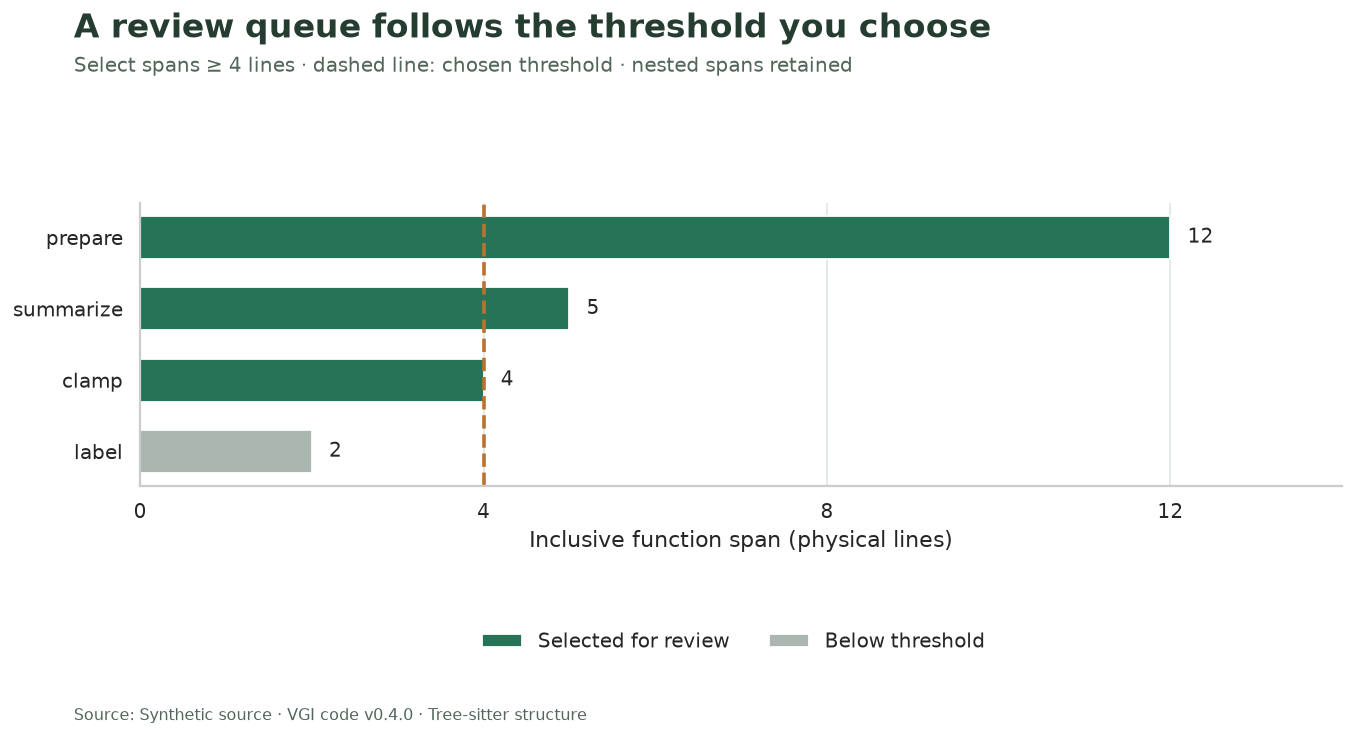

At **4 lines**, the queue contains **3 of 4 functions**: `prepare`, `summarize`, `clamp`. The selection changes review scope; it does not change the parsed source or make excluded functions correct. Parent and nested entries can cover the same lines.

In [15]:
queue = globals()["queue"]
display(queue[queue.selected])
fig, ax = plt.subplots(figsize=(10.8, 5.7))
colors = ["#267358" if value else "#aab6af" for value in queue.selected]
ax.barh(queue.name, queue.span_lines, color=colors, height=0.6)
for i, value in enumerate(queue.span_lines):
    ax.text(value + 0.2, i, str(int(value)), va="center", fontsize=11)
ax.axvline(MIN_SPAN_LINES, color="#bb722f", linestyle="--", linewidth=2)
ax.set_xlim(0, max(int(queue.span_lines.max()) + 2, MIN_SPAN_LINES + 2))
ax.set_xticks(sorted(set([0, 4, 8, 12, MIN_SPAN_LINES])))
ax.invert_yaxis()
ax.set_xlabel("Inclusive function span (physical lines)")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
fig.legend(
    handles=[
        Patch(facecolor="#267358", label="Selected for review"),
        Patch(facecolor="#aab6af", label="Below threshold"),
    ],
    loc="center",
    bbox_to_anchor=(0.55, 0.13),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "A review queue follows the threshold you choose",
    f"Select spans ≥ {MIN_SPAN_LINES} lines · dashed line: chosen threshold · nested spans retained",
    f"review-queue-{MIN_SPAN_LINES}.png",
    bottom=0.22,
)
chosen = queue.loc[queue.selected, "name"].tolist()
prose(
    f"At **{MIN_SPAN_LINES} lines**, the queue contains **{len(chosen)} of {len(queue)} functions**: "
    + (", ".join(f"`{name}`" for name in chosen) if chosen else "none")
    + ". The selection changes review scope; it does not change the parsed source or "
    "make excluded functions correct. Parent and nested entries can cover the same lines."
)

## Check structural consistency

Verify scalar and table agreement, capture text length, one-to-one joins and line
bounds. These relationships protect this analysis without prescribing a function
count, a threshold outcome or the absence of recovery in arbitrary inputs.

In [16]:
%%sql checks <<
SELECT 'Input inventory retained' AS check_name,
 abs((SELECT count(*) FROM files)-(SELECT count(*) FROM source_audit)) AS violations
UNION ALL
SELECT 'Unavailable source analysis remains NULL',count(*) FROM source_audit
WHERE (source_missing OR language IS NULL) AND
 (worker_loc IS NOT NULL OR function_count IS NOT NULL OR error_nodes IS NOT NULL OR missing_nodes IS NOT NULL)
UNION ALL
SELECT 'Function scalar and symbol table agree',
 abs((SELECT function_count FROM source_audit WHERE path='example.py')-(SELECT count(*) FROM symbols))
UNION ALL
SELECT 'Join preserves one row per symbol and capture',
 abs((SELECT count(*) FROM functions)-(SELECT count(*) FROM symbols))
 + abs((SELECT count(*) FROM functions)-(SELECT count(*) FROM definitions))
UNION ALL
SELECT 'Returned line bounds lie inside the module',count(*) FROM functions
WHERE start_line<1 OR end_line<start_line OR end_line>(SELECT physical_lines FROM source_audit WHERE path='example.py')
UNION ALL
SELECT 'Capture physical lines equal inclusive spans',count(*) FROM functions
WHERE code.main.count_lines(definition_source)<>span_lines
UNION ALL
SELECT 'Unique coverage does not exceed summed spans or file length',count(*)
FROM (SELECT count(DISTINCT line_number) AS covered FROM
 (SELECT unnest(range(start_line,end_line+1)) AS line_number FROM functions))
WHERE covered>(SELECT sum(span_lines) FROM functions)
 OR covered>(SELECT physical_lines FROM source_audit WHERE path='example.py');

In [17]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), "Structural consistency check failed."
prose(
    f"All **{len(checks)} consistency checks** pass. The parse results support this "
    "review queue and its line accounting; they do not evaluate the program's behavior."
)

,check_name,violations
0,Input inventory retained,0
1,Unavailable source analysis remains NULL,0
2,Function scalar and symbol table agree,0
3,Join preserves one row per symbol and capture,0
4,Returned line bounds lie inside the module,0
5,Capture physical lines equal inclusive spans,0
6,Unique coverage does not exceed summed spans o...,0


All **7 consistency checks** pass. The parse results support this review queue and its line accounting; they do not evaluate the program's behavior.

## One change to try

Predict the remaining candidates, then set `MIN_SPAN_LINES = 8` and run all cells.
Compare the queue and dashed threshold line. The source audit, symbol spans, full
captures and unique-line accounting should remain identical. The larger threshold
should leave only the enclosing function in this fixture. Reset to **4** afterward.

Keep the saved default intact with a separate executed copy:

```sh
uv run --locked python execute.py --parameters '{"MIN_SPAN_LINES":8}' \
  --output-dir validation/threshold-8
```

For a larger source inventory, keep language selection and unavailable inputs
explicit, retain both ERROR and MISSING recovery diagnostics, and choose review
rules that fit the language and codebase. Function spans include syntax and
nesting; they are not execution counts, cyclomatic complexity or proof of quality.

In [18]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)